In [1]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.utils import to_categorical

In [2]:
# Load dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

In [3]:
# Preprocessing
x_train = x_train.reshape(-1, 3072).astype('float32') / 255
x_test = x_test.reshape(-1, 3072).astype('float32') / 255
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [4]:
# Define model
model = Sequential([
    Dense(128, activation='relu', input_shape=(3072,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

C:\Users\kambi\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
# Compile and train
model.compile(optimizer=SGD(0.01),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10,
                    batch_size=128,
                    validation_data=(x_test, y_test))


Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - accuracy: 0.2802 - loss: 2.0316 - val_accuracy: 0.3286 - val_loss: 1.9107
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.3489 - loss: 1.8509 - val_accuracy: 0.3570 - val_loss: 1.8187
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.3720 - loss: 1.7834 - val_accuracy: 0.3778 - val_loss: 1.7630
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.3913 - loss: 1.7347 - val_accuracy: 0.3876 - val_loss: 1.7352
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.4022 - loss: 1.6972 - val_accuracy: 0.4096 - val_loss: 1.6751
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.4138 - loss: 1.6646 - val_accuracy: 0.4255 - val_loss: 1.6387
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.4243 - loss: 1.6355 - val_accuracy: 0.4248 - val_loss: 1.6311
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.4325 - loss: 1.6153 - val_acc

In [6]:
# Evaluate
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4109 - loss: 1.6401


[1.6401437520980835, 0.4108999967575073]

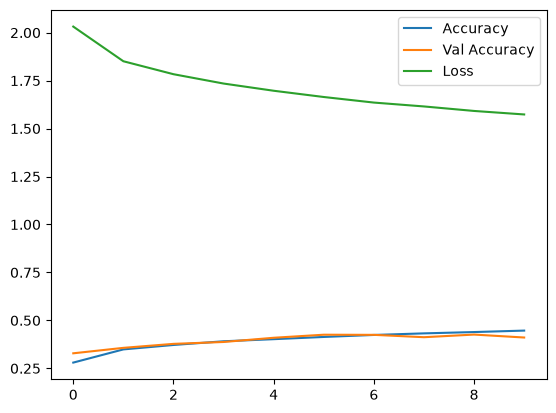

In [7]:
# Plot
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.plot(history.history['loss'], label='Loss')
plt.legend()
plt.show()